# Exercício 5 — Projeto Integrado de Limpeza
**Disciplina:** Ciência de Dados · **Etapa CRISP-DM:** Preparação dos Dados
**Dataset:** Dirty E-Commerce Data — SHEIN (Kaggle), 21 arquivos CSV (um por categoria de produto)

**Arquivos escolhidos para trabalhar:** `us-shein-womens_clothing-4620.csv` (roupas femininas) e `us-shein-electronics-4395.csv` (eletrônicos). Escolhi esses dois por serem categorias muito diferentes (preço médio de ≈ US$ 13 contra ≈ US$ 6 com cauda até US$ 1.199) e por terem **esquemas de colunas diferentes**, o que testa se o pipeline é realmente reutilizável. Ao final aplico o mesmo pipeline aos 21 arquivos.

In [1]:
# IMPORTAÇÕES
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import glob
import re

pd.set_option('display.float_format', '{:,.2f}'.format)
pd.set_option('display.width', 150)
pd.set_option('display.max_columns', 40)
pd.set_option('display.max_colwidth', 60)
sns.set_theme(style='whitegrid')

## Pergunta de negócio
> **Os produtos com desconto maior vendem mais?** Mais precisamente: em cada categoria, a chance de um produto ter selo de "muitas vendas recentes" (e o volume desse selo) aumenta com o percentual de desconto e muda conforme a faixa de preço?

Essa pergunta orienta as decisões de limpeza: preciso de **preço e desconto numéricos e confiáveis**, de **vendas recentes como número**, de **cada produto contado uma vez** (para a taxa não ser inflada por repetições) e de **cuidado com preços extremos**, que distorcem a comparação entre faixas.

In [2]:
# CARREGAMENTO DOS ARQUIVOS
arquivos = glob.glob('*.csv')
print(len(arquivos), 'arquivos CSV encontrados')

def achar(trecho):
    return next(a for a in arquivos if trecho in a)

arq_roupas = achar('womens_clothing')
arq_eletro = achar('electronics')

def nome_categoria(caminho):
    # 'us-shein-womens_clothing-4620.csv' -> 'womens_clothing'
    return re.sub(r'^us-shein-|-\d+\.csv$', '', caminho.split('\\')[-1].split('/')[-1])

bruto = {nome_categoria(a): pd.read_csv(a) for a in (arq_roupas, arq_eletro)}
for k, v in bruto.items():
    print(f'{k}: {v.shape[0]:,} linhas x {v.shape[1]} colunas')
bruto['womens_clothing'].head(3)

21 arquivos CSV encontrados
womens_clothing: 4,619 linhas x 8 colunas
electronics: 4,394 linhas x 9 colunas


,product-locatelabels-img src,color-count,goods-title-link,rank-title,rank-sub,price,discount,selling_proposition
0,https://img.ltwebstatic.com/images3_pi/2024/02/28/ec/170...,6.00,SHEIN SXY Women's Solid Color Backless Tie Neck Sleevele...,#1 Best Seller,In Sexy Women Apparel,$12.19,NaN,NaN
1,NaN,4.00,Knitted Color-Block Striped Hollow Out Short-Sleeved Top...,#6 Best Seller,In Short Sleeve Women Clothing,$16.59,-14%,NaN
2,NaN,7.00,Hollow Out Knit Crop Sweater With Bell Sleeve,#2 Best Sellers,in Women Sweaters,$9.19,-13%,NaN


## Diagnóstico inicial (registrar problemas ANTES de corrigir)

In [3]:
# DIAGNÓSTICO INICIAL (REGISTRAR PROBLEMAS ANTES DE CORRIGIR)
def titulo_bruto(df):
    """Título do produto no arquivo bruto: coluna principal, ou a coluna 'jump' quando a principal está vazia."""
    t = df['goods-title-link'] if 'goods-title-link' in df else pd.Series(np.nan, index=df.index)
    if 'goods-title-link--jump' in df:
        t = t.fillna(df['goods-title-link--jump'])
    return t

for nome, df in bruto.items():
    print('=' * 100); print(nome.upper(), df.shape)
    diag = pd.DataFrame({'tipo': df.dtypes.astype(str), 'ausentes': df.isna().sum(), '%_ausentes': df.isna().mean() * 100, 'únicos': df.nunique()})
    display(diag)
    t = titulo_bruto(df)
    print('Duplicatas exatas (linha inteira):                    ', df.duplicated().sum())
    print('Duplicatas por título + preço:                        ', (df.assign(_t=t).duplicated(['_t', 'price']) & t.notna()).sum(), '(inclui as exatas)')
    if 'goods-title-link--jump' in df:
        print("Linhas sem título em 'goods-title-link' mas com título em '--jump':", (df['goods-title-link'].isna() & df['goods-title-link--jump'].notna()).sum())
    print('Títulos totalmente ausentes:                          ', t.isna().sum())
    print('Títulos com espaços duplicados:                       ', t.dropna().str.contains(r'\s{2,}').sum())
    print("Preços fora do padrão '$12.34' (ex.: vírgula de milhar):", (~df['price'].str.fullmatch(r'\$\d+\.\d{2}')).sum())
    print("rank-sub começando com 'In' x 'in':                    ", df['rank-sub'].dropna().str[:3].value_counts().to_dict())

WOMENS_CLOTHING (4619, 8)


,tipo,ausentes,%_ausentes,únicos
product-locatelabels-img src,str,997,21.58,80
color-count,float64,2204,47.72,32
goods-title-link,str,0,0.00,4142
rank-title,str,3563,77.14,20
rank-sub,str,3563,77.14,480
price,str,0,0.00,1002
discount,str,1867,40.42,68
selling_proposition,str,1167,25.27,110


Duplicatas exatas (linha inteira):                     358
Duplicatas por título + preço:                         396 (inclui as exatas)
Títulos totalmente ausentes:                           0
Títulos com espaços duplicados:                        92
Preços fora do padrão '$12.34' (ex.: vírgula de milhar): 0
rank-sub começando com 'In' x 'in':                     {'In ': 840, 'in ': 216}
ELECTRONICS (4394, 9)


,tipo,ausentes,%_ausentes,únicos
goods-title-link--jump,str,4356,99.14,38
goods-title-link--jump href,str,4356,99.14,38
rank-title,str,3647,83.00,20
rank-sub,str,3647,83.00,217
price,str,0,0.00,666
discount,str,2869,65.29,79
selling_proposition,str,1227,27.92,96
color-count,float64,3256,74.10,18
goods-title-link,str,38,0.86,4029


Duplicatas exatas (linha inteira):                     34
Duplicatas por título + preço:                         131 (inclui as exatas)
Linhas sem título em 'goods-title-link' mas com título em '--jump': 38
Títulos totalmente ausentes:                           0
Títulos com espaços duplicados:                        157
Preços fora do padrão '$12.34' (ex.: vírgula de milhar): 1
rank-sub começando com 'In' x 'in':                     {'in ': 747}


In [4]:
# Os 21 arquivos têm o mesmo esquema?
colunas_por_arquivo = {nome_categoria(a): set(pd.read_csv(a, nrows=0).columns) for a in arquivos}
contagem = pd.Series([c for cols in colunas_por_arquivo.values() for c in cols]).value_counts().rename('qtd_arquivos').to_frame()
print('Colunas e em quantos dos', len(arquivos), 'arquivos aparecem:')
contagem

Colunas e em quantos dos 21 arquivos aparecem:


,qtd_arquivos
discount,21
goods-title-link,21
price,21
selling_proposition,20
rank-sub,19
rank-title,19
goods-title-link--jump href,17
goods-title-link--jump,17
color-count,14
blackfridaybelts-content,2


**Problemas encontrados (diagnóstico, antes de qualquer correção):**

| # | Problema | Onde | Por que importa |
|---|---|---|---|
| 1 | **Preço como texto** (`'$12.19'`, `'$1,199.00'` com vírgula de milhar) | todos os arquivos | Não dá para somar, comparar nem ordenar |
| 2 | **Desconto como texto** (`'-14%'`) | todos | Idem; o sinal negativo atrapalha |
| 3 | **Vendas recentes como texto** (`'100+ sold recently'`, `'1.5k+ ...'`, `'10k+ ...'`) | `selling_proposition` | A variável central da pergunta de negócio não é numérica |
| 4 | **Posição no ranking embutida em texto** (`'#6 Best Seller'`) e `rank-sub` com `In`/`in` | `rank-title`, `rank-sub` | Mesma categoria escrita de duas formas |
| 5 | **Esquemas diferentes** entre arquivos (colunas presentes em só alguns) | 21 arquivos | O pipeline precisa tolerar colunas faltando |
| 6 | **Título em outra coluna** em algumas linhas (`goods-title-link--jump`) e **títulos ausentes** | eletrônicos, brinquedos | A mesma informação em dois lugares: ao olhar só uma coluna, o título "falta" |
| 7 | **Duplicatas**: exatas **e** não-exatas (mesmo título e preço, mas rank/discount/selo diferentes) | todos | Inflam contagens e taxas |
| 8 | **Ausentes com significado diferente**: `discount` vazio = sem desconto; `selling_proposition` vazio = sem selo; `color-count` vazio = não se aplica | todos | Tratar tudo igual (média, remover) seria errado |
| 9 | **Espaços duplicados** nos títulos | todos | Impedem detectar o mesmo produto escrito de duas formas |
| 10 | **Preços extremos** (até US$ 1.199 em eletrônicos, mediana ≈ US$ 2) | eletrônicos principalmente | Distorcem médias e comparações |
| 11 | Colunas inúteis para a pergunta (`img src`, `href`, `blackfridaybelts-*`) | alguns | Ruído, muitas quase vazias |

## Funções do pipeline
**Ordem escolhida e justificativa:**
1. `corrigir_tipos` — primeiro, porque todas as etapas seguintes dependem de números e de um esquema único.
2. `padronizar_textos` — antes das duplicatas, para que `"A  B"` e `"A B"` sejam reconhecidos como o mesmo produto.
3. `tratar_duplicatas` — **antes dos ausentes**: a escolha de qual linha repetida manter usa "qual é a mais completa", e isso se perderia se eu já tivesse preenchido os vazios. E antes dos outliers, para que cópias repetidas não distorçam os quartis.
4. `tratar_ausentes` — com a base já sem repetições.
5. `criar_features` — depende de preço e desconto já limpos (e preenchidos).
6. `tratar_outliers` — por último: precisa dos preços finais e já sem duplicatas; a feature `preco_original_estimado` usa o preço **real**, não o limitado.

In [5]:
# FUNÇÕES DO PIPELINE
def _col(df, nome):
    """Coluna se existir; senão uma série de NA (tolera esquemas diferentes entre arquivos)."""
    return df[nome] if nome in df else pd.Series(pd.NA, index=df.index, dtype='object')


def corrigir_tipos(df):
    """Unifica o esquema e converte texto em número: preço, desconto, vendas, ranking, cores."""
    df = df.copy()
    out = pd.DataFrame(index=df.index)
    out['titulo'] = titulo_bruto(df)
    # '$1,199.00' -> 1199.0 ; '$12.19' -> 12.19
    out['preco'] = pd.to_numeric(_col(df, 'price').astype('string').str.replace(r'[^\d.]', '', regex=True), errors='coerce')
    # '-14%' -> 14.0
    out['desconto_pct'] = pd.to_numeric(_col(df, 'discount').astype('string').str.extract(r'(\d+(?:\.\d+)?)')[0], errors='coerce')
    out['qtd_cores'] = pd.to_numeric(_col(df, 'color-count'), errors='coerce').astype('Int64')
    # '#6 Best Seller' -> 6
    out['rank_posicao'] = pd.to_numeric(_col(df, 'rank-title').astype('string').str.extract(r'#(\d+)')[0], errors='coerce').astype('Int64')
    out['rank_sub'] = _col(df, 'rank-sub').astype('string')
    # '100+ sold recently' -> 100 ; '1.5k+ sold recently' -> 1500 ; '10k+ ...' -> 10000
    sp = _col(df, 'selling_proposition').astype('string').str.extract(r'(?i)([\d.]+)\s*(k?)\s*\+')
    mult = sp[1].fillna('').str.lower().eq('k').map({True: 1000, False: 1})
    out['vendas_recentes_min'] = pd.to_numeric(sp[0], errors='coerce') * mult
    return out


def padronizar_textos(df):
    """Título sem espaços repetidos/pontas; categoria do ranking em minúsculas e sem o prefixo 'in'."""
    df = df.copy()
    df['titulo'] = df['titulo'].astype('string').str.replace(r'\s+', ' ', regex=True).str.strip()
    df['rank_categoria'] = (df['rank_sub'].str.strip().str.lower()
                            .str.replace(r'^in\s+', '', regex=True).str.replace(r'\s+', ' ', regex=True))
    return df.drop(columns='rank_sub')


def tratar_duplicatas(df):
    """Remove repetições do mesmo produto (mesmo título + preço), mantendo a linha mais completa."""
    df = df.copy()
    ordem = df.assign(_n=df.notna().sum(axis=1)).sort_values('_n', ascending=False, kind='stable').index
    ordenado = df.loc[ordem]
    repetida = ordenado.duplicated(['titulo', 'preco'], keep='first') & ordenado['titulo'].notna()   # sem título não dá para afirmar que repete
    return df.drop(index=repetida[repetida].index)


def tratar_ausentes(df):
    """Regras por coluna, conforme o SIGNIFICADO da ausência (ver tabela do relatório)."""
    df = df.copy()
    df = df[df['titulo'].notna() & df['preco'].notna()]                    # sem título ou preço não há o que analisar
    if df['vendas_recentes_min'].notna().any():
        df['tem_selo_vendas'] = df['vendas_recentes_min'].notna().astype('boolean')   # guarda a informação antes de preencher
        df['vendas_recentes_min'] = df['vendas_recentes_min'].fillna(0)               # sem selo = abaixo do mínimo exibido
    else:
        # o arquivo nem tem a coluna (ex.: swimwear): a informação é DESCONHECIDA, não zero
        df['tem_selo_vendas'] = pd.Series(pd.NA, index=df.index, dtype='boolean')
    df['desconto_pct'] = df['desconto_pct'].fillna(0)                       # desconto vazio = sem desconto
    # qtd_cores e rank_* ficam como NA de propósito: "não se aplica" não é "zero"
    return df


def criar_features(df):
    """Variáveis úteis para a pergunta: preço original estimado, economia, faixas de desconto e de preço."""
    df = df.copy()
    df['tem_desconto'] = df['desconto_pct'] > 0
    df['preco_original_estimado'] = df['preco'] / (1 - df['desconto_pct'].clip(upper=99) / 100)
    df['economia_usd'] = df['preco_original_estimado'] - df['preco']
    df['faixa_desconto'] = pd.cut(df['desconto_pct'], bins=[-0.1, 0, 20, 40, 60, 100],
                                  labels=['sem desconto', '1–20%', '21–40%', '41–60%', '>60%'])
    df['faixa_preco'] = pd.qcut(df['preco'], 3, labels=['baixo', 'médio', 'alto'], duplicates='drop')
    if df['rank_posicao'].notna().any():
        df['is_best_seller'] = df['rank_posicao'].notna().astype('boolean')
    else:
        df['is_best_seller'] = pd.Series(pd.NA, index=df.index, dtype='boolean')   # arquivo sem ranking: desconhecido
    return df


def tratar_outliers(df, k=1.5):
    """Detecta extremos de preço por IQR na escala log (preço é assimétrico). NÃO apaga: marca e cria versão limitada."""
    df = df.copy()
    lp = np.log(df['preco'])
    q1, q3 = lp.quantile([0.25, 0.75])
    inf, sup = q1 - k * (q3 - q1), q3 + k * (q3 - q1)
    df['preco_outlier'] = (lp < inf) | (lp > sup)
    df['preco_limitado'] = np.exp(lp.clip(inf, sup))
    df.attrs['limites_preco'] = (float(np.exp(inf)), float(np.exp(sup)))
    return df

## Execução do pipeline
A função `pipeline()` encadeia as etapas e registra quantas linhas cada uma removeu, para documentar o impacto de cada decisão.

In [6]:
# EXECUÇÃO DO PIPELINE
def pipeline(df_bruto, categoria):
    log = {'categoria': categoria, 'linhas_entrada': len(df_bruto)}
    df = corrigir_tipos(df_bruto);      log['após_tipos'] = len(df)
    df = padronizar_textos(df)
    n = len(df); df = tratar_duplicatas(df);  log['duplicatas_removidas'] = n - len(df)
    n = len(df); df = tratar_ausentes(df);    log['sem_título_ou_preço_removidas'] = n - len(df)
    df = criar_features(df)
    df = tratar_outliers(df);           log['outliers_de_preço_marcados'] = int(df['preco_outlier'].sum())
    df.insert(0, 'categoria', categoria)
    log['linhas_saída'] = len(df)
    return df.reset_index(drop=True), log

limpo, logs = {}, []
for nome, df in bruto.items():
    limpo[nome], lg = pipeline(df, nome)
    logs.append(lg)
pd.DataFrame(logs).set_index('categoria').T

categoria,womens_clothing,electronics
linhas_entrada,4619,4394
após_tipos,4619,4394
duplicatas_removidas,396,131
sem_título_ou_preço_removidas,0,0
outliers_de_preço_marcados,91,265
linhas_saída,4223,4263


In [7]:
limpo['womens_clothing'].head(5).T

,0,1,2,3,4
categoria,womens_clothing,womens_clothing,womens_clothing,womens_clothing,womens_clothing
titulo,SHEIN SXY Women's Solid Color Backless Tie Neck Sleevele...,Knitted Color-Block Striped Hollow Out Short-Sleeved Top...,Hollow Out Knit Crop Sweater With Bell Sleeve,SHEIN EZwear Women's Short Sleeve T-Shirt And Flared Leg...,SHEIN SXY Solid Color Zipper Half Front Fashionable Tank...
preco,12.19,16.59,9.19,14.29,14.84
desconto_pct,0,14,13,0,8
qtd_cores,6,4,7,9,<NA>
rank_posicao,1,6,2,<NA>,<NA>
vendas_recentes_min,0.00,0.00,0.00,"10,000.00","1,500.00"
rank_categoria,sexy women apparel,short sleeve women clothing,women sweaters,<NA>,<NA>
tem_selo_vendas,False,False,False,True,True
tem_desconto,False,True,True,False,True


In [8]:
print('Tipos finais (roupas femininas):')
limpo['womens_clothing'].dtypes.astype(str).to_frame('tipo').T

Tipos finais (roupas femininas):


,categoria,titulo,preco,desconto_pct,qtd_cores,rank_posicao,vendas_recentes_min,rank_categoria,tem_selo_vendas,tem_desconto,preco_original_estimado,economia_usd,faixa_desconto,faixa_preco,is_best_seller,preco_outlier,preco_limitado
tipo,str,string,Float64,Int64,Int64,Int64,Float64,string,boolean,boolean,Float64,Float64,category,category,boolean,boolean,Float64


## Tabela "antes x depois"

In [9]:
# TABELA ANTES x DEPOIS
def indicadores(df, bruto_flag):
    if bruto_flag:
        t = titulo_bruto(df)
        dup_chave = df.assign(_t=t).duplicated(['_t', 'price']) & t.notna()
        return {'linhas': len(df), '% ausentes (todas as células)': df.isna().mean().mean() * 100,
                'duplicatas exatas': int(df.duplicated().sum()), 'duplicatas título+preço': int(dup_chave.sum()),
                'colunas numéricas': int(df.select_dtypes('number').shape[1]), 'colunas de texto': int(df.select_dtypes(exclude='number').shape[1]),
                'preço é numérico?': pd.api.types.is_numeric_dtype(df['price']), 'desconto é numérico?': pd.api.types.is_numeric_dtype(df['discount'])}
    dup_chave = df.duplicated(['titulo', 'preco'])
    return {'linhas': len(df), '% ausentes (todas as células)': df.isna().mean().mean() * 100,
            'duplicatas exatas': int(df.duplicated().sum()), 'duplicatas título+preço': int(dup_chave.sum()),
            'colunas numéricas': int(df.select_dtypes('number').shape[1]), 'colunas de texto': int(df.select_dtypes(exclude=['number', 'bool']).shape[1]),
            'preço é numérico?': pd.api.types.is_numeric_dtype(df['preco']), 'desconto é numérico?': pd.api.types.is_numeric_dtype(df['desconto_pct'])}

antes_depois = pd.concat({nome: pd.DataFrame({'antes': indicadores(bruto[nome], True), 'depois': indicadores(limpo[nome], False)}) for nome in bruto}, axis=1)
antes_depois

womens_clothing        electronics       
                                        antes depois       antes depois
linhas                                   4619   4223        4394   4263
% ausentes (todas as células)           36.16  11.90       59.16  14.15
duplicatas exatas                         358      0          34      0
duplicatas título+preço                   396      0         131      0
colunas numéricas                           1      8           1      8
colunas de texto                            7      5           8      5
preço é numérico?                       False   True       False   True
desconto é numérico?                    False   True       False   True

In [10]:
# Antes x depois, coluna a coluna (campos-chave)
mapa = {'titulo': 'goods-title-link', 'preco': 'price', 'desconto_pct': 'discount', 'vendas_recentes_min': 'selling_proposition', 'qtd_cores': 'color-count'}
linhas = []
for nome in bruto:
    for novo, velho in mapa.items():
        linhas.append({'arquivo': nome, 'campo': novo,
                       'tipo antes': str(bruto[nome][velho].dtype) if velho in bruto[nome] else '(coluna inexistente)',
                       'tipo depois': str(limpo[nome][novo].dtype),
                       '% ausente antes': bruto[nome][velho].isna().mean() * 100 if velho in bruto[nome] else np.nan,
                       '% ausente depois': limpo[nome][novo].isna().mean() * 100})
pd.DataFrame(linhas).set_index(['arquivo', 'campo'])

tipo antes tipo depois  % ausente antes  % ausente depois
arquivo         campo                                                                        
womens_clothing titulo                     str      string             0.00              0.00
                preco                      str     Float64             0.00              0.00
                desconto_pct               str       Int64            40.42              0.00
                vendas_recentes_min        str     Float64            25.27              0.00
                qtd_cores              float64       Int64            47.72             48.64
electronics     titulo                     str      string             0.86              0.00
                preco                      str     Float64             0.00              0.00
                desconto_pct               str       Int64            65.29              0.00
                vendas_recentes_min        str     Float64            27.92              0.00
                qtd_cores              float64       Int64            74.10             74.69

**Como ler a tabela:** o "% de ausentes" cai de ≈ 36% para ≈ 12% (roupas) e de ≈ 59% para ≈ 14% (eletrônicos), mas é preciso ser honesto sobre **por que**: em boa parte é porque descartei colunas inúteis (imagem, link) e porque preenchi por regra os vazios que na verdade significam "sem desconto" e "sem selo" (não houve imputação estatística). Os ausentes que **realmente** representam falta de informação (`qtd_cores`, `rank_*`) permanecem, e isso é intencional. O ganho mais concreto está nas linhas de **duplicatas** (358 → 0 e 34 → 0 exatas; 396 → 0 e 131 → 0 por título + preço) e nos **tipos**: preço e desconto passam de texto para número.

## Visualizações

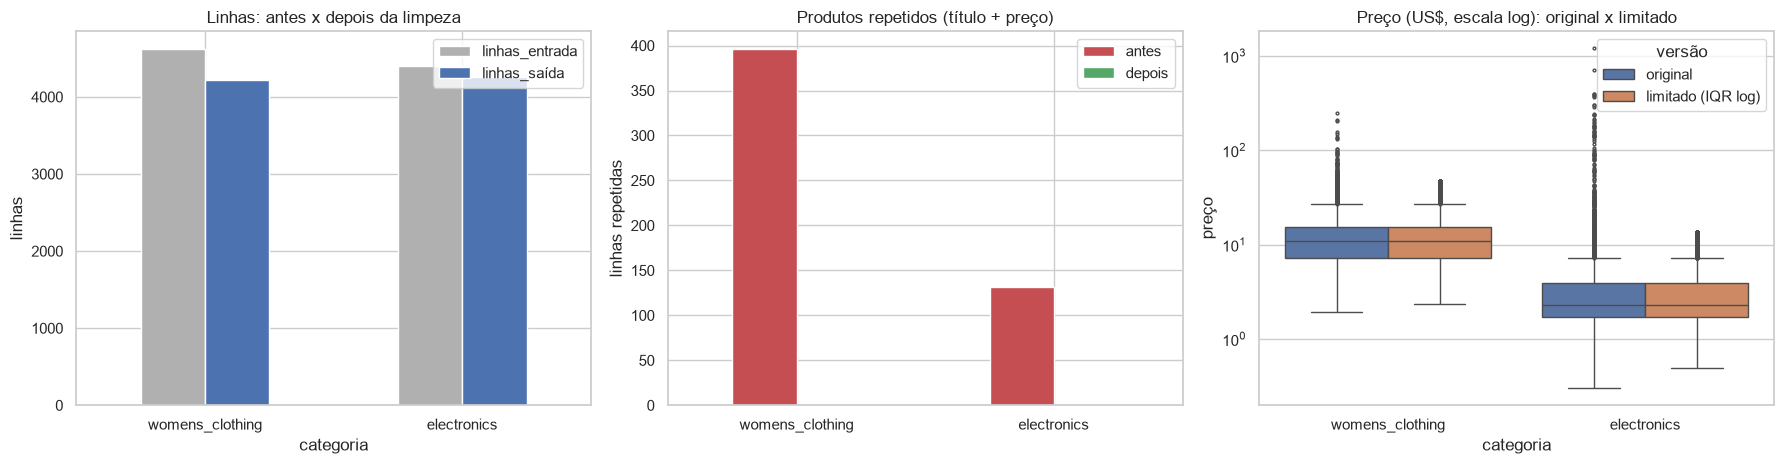

In [11]:
# VISUALIZAÇÕES (1) — duplicatas e linhas antes x depois; (2) preços antes x depois do tratamento de outliers
fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))

# (1a) Linhas em cada etapa
df_log = pd.DataFrame(logs).set_index('categoria')
df_log[['linhas_entrada', 'linhas_saída']].plot.bar(ax=axes[0], color=['#B0B0B0', '#4C72B0'], rot=0)
axes[0].set_title('Linhas: antes x depois da limpeza'); axes[0].set_ylabel('linhas')

# (1b) Duplicatas por título+preço
dup = pd.DataFrame({nome: {'antes': indicadores(bruto[nome], True)['duplicatas título+preço'], 'depois': indicadores(limpo[nome], False)['duplicatas título+preço']} for nome in bruto}).T
dup.plot.bar(ax=axes[1], color=['#C44E52', '#55A868'], rot=0)
axes[1].set_title('Produtos repetidos (título + preço)'); axes[1].set_ylabel('linhas repetidas')

# (2) preços: cauda longa vs versão limitada (escala log no eixo y)
dados = pd.concat([limpo[n].assign(versão='original') [['categoria', 'versão']].assign(preço=limpo[n]['preco']) for n in limpo] +
                  [limpo[n].assign(versão='limitado (IQR log)')[['categoria', 'versão']].assign(preço=limpo[n]['preco_limitado']) for n in limpo])
sns.boxplot(data=dados, x='categoria', y='preço', hue='versão', ax=axes[2], fliersize=2)
axes[2].set_yscale('log'); axes[2].set_title('Preço (US$, escala log): original x limitado')
plt.tight_layout(); plt.show()

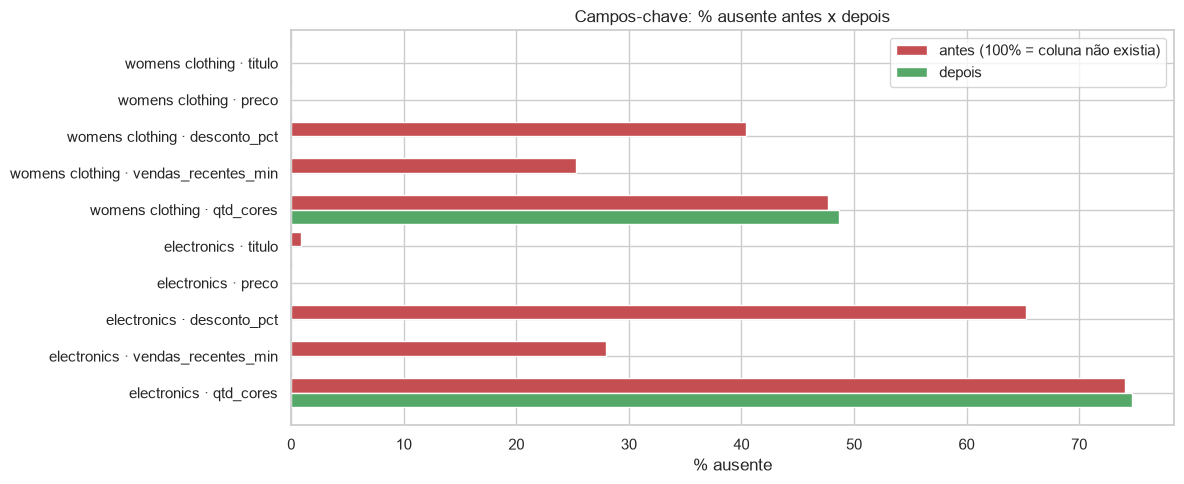

In [12]:
# VISUALIZAÇÕES (3) — preenchimento dos campos-chave antes x depois (campos-chave)
chaves = pd.DataFrame(linhas)
chaves['arq_campo'] = chaves['arquivo'].str.replace('_', ' ') + ' · ' + chaves['campo']
fig, ax = plt.subplots(figsize=(12, 5))
y = np.arange(len(chaves))
ax.barh(y - 0.2, chaves['% ausente antes'].fillna(100), height=0.4, color='#C44E52', label='antes (100% = coluna não existia)')
ax.barh(y + 0.2, chaves['% ausente depois'], height=0.4, color='#55A868', label='depois')
ax.set_yticks(y); ax.set_yticklabels(chaves['arq_campo']); ax.invert_yaxis(); ax.set_xlabel('% ausente'); ax.legend()
ax.set_title('Campos-chave: % ausente antes x depois')
plt.tight_layout(); plt.show()

## Relatório e respostas às perguntas de reflexão
### Resposta à pergunta de negócio (resultado da base limpa)

produtos  pct_com_selo_vendas  mediana_vendas_do_selo
categoria       faixa_desconto                                                       
electronics     sem desconto        2782                75.90                  600.00
                1–20%                601                73.20                  300.00
                21–40%               527                56.00                  200.00
                41–60%               246                66.30                  200.00
                >60%                 107                66.40                  200.00
womens_clothing sem desconto        1719                72.40                  500.00
                1–20%               2155                73.70                2,300.00
                21–40%               206                90.80                  800.00
                41–60%               130                83.80                  900.00
                >60%                  13                61.50                   30.00

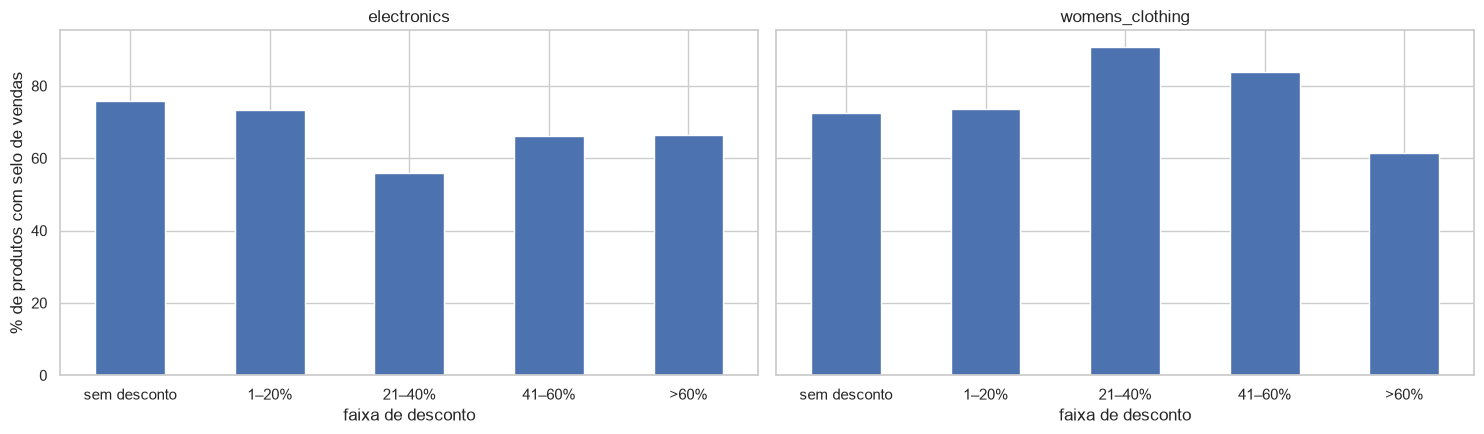

Correlação de Spearman entre desconto_pct e vendas_recentes_min:
categoria
electronics       -0.21
womens_clothing    0.14
dtype: float64


In [13]:
# Resposta à pergunta de negócio: o desconto maior está associado a mais "vendas recentes"?
tudo = pd.concat(limpo.values(), ignore_index=True)
resp = (tudo.groupby(['categoria', 'faixa_desconto'], observed=True)
            .agg(produtos=('titulo', 'size'),
                 pct_com_selo_vendas=('tem_selo_vendas', lambda s: s.mean() * 100),
                 mediana_vendas_do_selo=('vendas_recentes_min', lambda s: s[s > 0].median()))
            .round(1))
display(resp)

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5), sharey=True)
for ax, (nome, g) in zip(axes, tudo.groupby('categoria')):
    t = g.groupby('faixa_desconto', observed=True)['tem_selo_vendas'].mean() * 100
    t.plot.bar(ax=ax, color='#4C72B0', rot=0); ax.set_title(nome); ax.set_xlabel('faixa de desconto'); ax.set_ylabel('% de produtos com selo de vendas')
plt.tight_layout(); plt.show()

print('Correlação de Spearman entre desconto_pct e vendas_recentes_min:')
print(tudo.groupby('categoria').apply(lambda g: g['desconto_pct'].corr(g['vendas_recentes_min'], method='spearman'), include_groups=False).round(3))

In [14]:
# Experimento para a pergunta de reflexão 2: a ORDEM das etapas muda o resultado?
def n_outliers(df, col='preco'):
    lp = np.log(df[col]); q1, q3 = lp.quantile([0.25, 0.75]); iqr = q3 - q1
    return int(((lp < q1 - 1.5 * iqr) | (lp > q3 + 1.5 * iqr)).sum()), float(np.exp(q3 + 1.5 * iqr))

linhas_ordem = []
for nome, df in bruto.items():
    t = corrigir_tipos(df); t = padronizar_textos(t)
    a_antes = n_outliers(t[t['preco'].notna()])                       # outliers ANTES de tirar duplicatas
    d = tratar_duplicatas(t)
    a_depois = n_outliers(d[d['preco'].notna()])                      # outliers DEPOIS
    linhas_ordem.append({'arquivo': nome, 'outliers (antes das duplicatas)': a_antes[0], 'limite sup. (antes) US$': a_antes[1],
                         'outliers (depois das duplicatas)': a_depois[0], 'limite sup. (depois) US$': a_depois[1]})

    # e a ordem "ausentes antes de duplicatas": preenchendo vazios antes, todas as linhas parecem completas
    # e o desempate entre repetidas deixa de escolher a mais informativa
    pre = tratar_duplicatas(tratar_ausentes(t))                       # ordem alternativa: preenche e depois remove repetidas
    esc = tratar_ausentes(d)                                          # ordem escolhida: remove repetidas e depois preenche
    linhas_ordem[-1]['linhas c/ posição de ranking (alternativa)'] = int(pre['rank_posicao'].notna().sum())
    linhas_ordem[-1]['linhas c/ posição de ranking (escolhida)'] = int(esc['rank_posicao'].notna().sum())
    linhas_ordem[-1]['linhas c/ selo de vendas (alternativa)'] = int(pre['tem_selo_vendas'].sum())
    linhas_ordem[-1]['linhas c/ selo de vendas (escolhida)'] = int(esc['tem_selo_vendas'].sum())
    linhas_ordem[-1]['linhas c/ nº de cores (alternativa)'] = int(pre['qtd_cores'].notna().sum())
    linhas_ordem[-1]['linhas c/ nº de cores (escolhida)'] = int(esc['qtd_cores'].notna().sum())
pd.DataFrame(linhas_ordem).set_index('arquivo').T

arquivo,womens_clothing,electronics
outliers (antes das duplicatas),92.00,280.00
limite sup. (antes) US$,47.40,13.29
outliers (depois das duplicatas),91.00,265.00
limite sup. (depois) US$,46.72,13.55
linhas c/ posição de ranking (alternativa),979.00,731.00
linhas c/ posição de ranking (escolhida),979.00,729.00
linhas c/ selo de vendas (alternativa),"3,138.00","3,077.00"
linhas c/ selo de vendas (escolhida),"3,138.00","3,080.00"
linhas c/ nº de cores (alternativa),"2,169.00","1,077.00"
linhas c/ nº de cores (escolhida),"2,169.00","1,079.00"


**Resposta de negócio:** a resposta **depende da categoria** e, em nenhuma, o desconto explica muito:
- **Roupas femininas:** a proporção de produtos com selo de vendas sobe de 72% (sem desconto) para **91% (21–40%)** e **84% (41–60%)**, e a correlação de Spearman é **+0,14** (positiva, fraca). A faixa >60% tem só 13 produtos, pequena demais para concluir algo.
- **Eletrônicos:** acontece o contrário: de 76% (sem desconto) cai para **56% (21–40%)**, e a correlação é **−0,21** (negativa, fraca). Aqui, o desconto grande parece associado a produtos *menos* vendidos, possivelmente liquidação de itens parados.
- A leitura honesta é que o desconto, **sozinho**, é um preditor fraco e inconsistente entre categorias (|ρ| ≤ 0,21): não dá para afirmar que "desconto maior vende mais". Há três ressalvas que a limpeza deixou explícitas: (1) só existe selo para produtos com **100+** vendas recentes, então a variável é *censurada* (não sabemos quanto vendem os produtos sem selo); (2) o **desconto exibido** depende da forma como o preço original é calculado pela loja; (3) há viés de seleção, pois a base reúne produtos de listas de ranking e de categorias populares.

### Decisões tomadas e justificativas

| Etapa | Decisão | Justificativa | Impacto |
|---|---|---|---|
| Tipos | Preço, desconto, vendas e posição de ranking viram numéricos; esquema unificado (título lido da coluna principal ou da `--jump`) | Sem números não há análise; o mesmo conteúdo estava em colunas diferentes | Preço/desconto/vendas passam de texto para número em todos os arquivos |
| Textos | Espaços repetidos removidos; `rank_sub` em minúsculas, sem `in` | `In` e `in` eram a mesma categoria; espaços impedem comparar títulos | Categorias de ranking unificadas |
| Duplicatas | Remover repetição por **título + preço**, mantendo a linha **mais completa** | Dup. exatas não pegam o mesmo produto com rank/selo diferentes; manter a mais completa preserva informação | Ver tabela `antes x depois` |
| Ausentes | `desconto` vazio → **0**; `vendas` vazio → **0** + coluna `tem_selo_vendas`; `qtd_cores`/`rank_*` mantidos como ausentes; sem título ou sem preço → **removidas** | Cada vazio tem um significado diferente; apagar ou usar a média seria inventar informação | Poucas linhas perdidas |
| Esquemas diferentes | Se o arquivo não tem a coluna (ex.: `selling_proposition` em `swimwear`, ranking em 2 arquivos), o campo derivado fica **desconhecido (`NA`)**, nunca 0/`False` | A primeira versão do pipeline marcava `swimwear` como "0% com selo de vendas", o que era falso: a informação não existe no arquivo. Foi detectado ao rodar nos 21 arquivos | Evita conclusões erradas na base consolidada |
| Features | `preco_original_estimado`, `economia_usd`, `faixa_desconto`, `faixa_preco`, `is_best_seller`, `tem_desconto` | Respondem diretamente à pergunta de negócio | 6 colunas novas |
| Outliers | **Marcar** (IQR na escala log) e criar `preco_limitado`; **não apagar** | Preços altos (ex.: eletrônicos de centenas de dólares) são produtos reais, mas distorcem médias | Colunas `preco_outlier` e `preco_limitado` |

### Reutilização: o mesmo pipeline nos 21 arquivos

In [15]:
# Aplicando o pipeline, sem alterar nenhuma função, aos 21 arquivos (prova de reutilização)
resultados, todos = [], {}
for a in sorted(arquivos):
    nome = nome_categoria(a)
    df_b = pd.read_csv(a)
    try:
        df_l, lg = pipeline(df_b, nome)
        lg.update({'colunas_originais': df_b.shape[1], 'colunas_finais': df_l.shape[1], 'ok': True})
        todos[nome] = df_l
    except Exception as e:
        lg = {'categoria': nome, 'ok': False, 'erro': repr(e)}
    resultados.append(lg)
res_all = pd.DataFrame(resultados).set_index('categoria')
print('Arquivos processados com sucesso:', int(res_all['ok'].sum()), 'de', len(res_all))
res_all.drop(columns=['ok'], errors='ignore')

Arquivos processados com sucesso: 21 de 21


,linhas_entrada,após_tipos,duplicatas_removidas,sem_título_ou_preço_removidas,outliers_de_preço_marcados,linhas_saída,colunas_originais,colunas_finais
categoria,,,,,,,,
appliances,3986,3986,265,0,18,3721,8,17
automotive,4109,4109,256,0,109,3853,6,17
baby_and_maternity,4432,4432,48,0,53,4384,7,17
bags_and_luggage,4298,4298,87,0,25,4211,9,17
beauty_and_health,4266,4266,78,0,191,4188,9,17
curve,2848,2848,131,1,41,2716,9,17
electronics,4394,4394,131,0,265,4263,9,17
home_and_kitchen,3719,3719,198,0,72,3521,6,17
home_textile,3882,3882,239,0,42,3643,9,17


In [16]:
consolidado = pd.concat(todos.values(), ignore_index=True)
print('Base consolidada limpa:', consolidado.shape)
print('Nulos nas colunas obrigatórias (titulo, preco, desconto_pct):', consolidado[['titulo', 'preco', 'desconto_pct']].isna().sum().sum())
print('Preços <= 0:', (consolidado['preco'] <= 0).sum(), '| descontos fora de [0, 100]:', (~consolidado['desconto_pct'].between(0, 100)).sum())
consolidado.groupby('categoria').agg(produtos=('titulo', 'size'), preco_mediano=('preco', 'median'), desconto_medio=('desconto_pct', 'mean'),
                                     pct_com_selo=('tem_selo_vendas', lambda s: s.mean() * 100)).round(1)

Base consolidada limpa: (78232, 17)
Nulos nas colunas obrigatórias (titulo, preco, desconto_pct): 0
Preços <= 0: 0 | descontos fora de [0, 100]: 0


,produtos,preco_mediano,desconto_medio,pct_com_selo
categoria,,,,
appliances,3721,16.50,17.30,35.10
automotive,3853,3.40,10.00,70.20
baby_and_maternity,4384,7.70,10.60,79.10
bags_and_luggage,4211,5.50,23.10,84.80
beauty_and_health,4188,2.40,16.30,76.20
curve,2716,12.00,14.20,80.10
electronics,4263,2.30,10.60,72.20
home_and_kitchen,3521,2.60,13.40,65.30
home_textile,3643,6.50,11.70,71.60


### Respostas às perguntas de reflexão
**1. Qual problema foi o mais difícil de perceber? Por que ele passaria despercebido em uma análise rápida?**
O mais difícil foi o conjunto das **duplicatas não exatas** junto com o **título em outra coluna**. Em uma análise rápida, `df.duplicated().sum()` retorna um número (358 nas roupas) e dá a impressão de que o problema está resolvido, mas o critério título + preço encontra mais linhas repetidas (396), porque o mesmo produto reaparece com posição de ranking, desconto ou selo diferentes. Já o título "ausente" nos eletrônicos e nos brinquedos só se explica olhando uma **coluna diferente** (`goods-title-link--jump`): quem olhasse só `goods-title-link` concluiria que eram produtos sem nome e os descartaria ou, pior, os trataria como "duplicados entre si" (valores `NaN` iguais). Outros problemas são "fáceis de ver" no `head()` (o `$`, o `%`), mas esses dois só aparecem quando se pergunta *o que significa cada linha* e se conhece o formato do dado.

**2. A ordem das etapas importa? Dê um exemplo em que tratar outliers antes dos ausentes (ou vice-versa) mudaria o resultado.**
Importa, mas o experimento acima mostra que **neste dataset o efeito é modesto**, e vale registrar isso com honestidade. Calculando os **limites de outlier de preço antes de remover as duplicatas**, os eletrônicos teriam **280 outliers e limite superior de US$ 13,29**, contra **265 e US$ 13,55** depois, porque os produtos repetidos pesam duas vezes nos quartis. Nas roupas, 92 contra 91. Já a ordem entre *ausentes* e *duplicatas* mudou no máximo 3 linhas, porque quase não há empates entre repetidas. Ou seja, aqui a ordem não muda a conclusão, mas em uma base com mais repetições ou com valores extremos repetidos mudaria. Os argumentos de princípio são: (a) se eu **preenchesse os vazios antes das duplicatas**, todas as linhas ficariam "completas" e eu perderia o critério para escolher a mais informativa; (b) se **limitasse o preço antes de criar `preco_original_estimado`**, a economia calculada ficaria errada para os produtos caros; (c) se **imputasse a média de preço antes de tratar outliers**, os extremos contaminariam o valor imputado (a média é muito sensível a eles) e isso aumentaria a distorção. A regra prática: primeiro corrigir o que é *erro de forma* (tipos, textos, duplicatas), depois o que é *falta* (ausentes) e só então o que é *extremo estatístico* (outliers), pois cada decisão usa estatísticas que as etapas anteriores alteram.

**3. Se a pergunta de negócio fosse outra, qual das suas decisões de limpeza você mudaria?**
Depende da pergunta, mas as decisões mais sensíveis são: (a) **`desconto` vazio → 0**: se a pergunta fosse sobre *política de descontos*, eu trataria o vazio como "desconhecido" e não como "sem desconto", para não inflar o grupo "sem desconto"; (b) **outliers**: se a pergunta fosse sobre *produtos premium* ou sobre *faturamento*, os preços altos seriam justamente o foco, e eu **não usaria** `preco_limitado`; se fosse *preço típico por categoria*, eu usaria a mediana e a versão limitada; (c) **duplicatas por título + preço**: se a pergunta fosse sobre *quantas vezes um produto aparece em rankings*, as repetições seriam a informação e eu **não as removeria**; (d) **`vendas` vazio → 0**: se a pergunta fosse sobre volume de vendas real, o 0 seria enganoso (o certo é "menos de 100"), e eu trabalharia com a variável binária de selo ou com um modelo para dados censurados. Isso mostra que **a limpeza depende do objetivo**: por isso cada decisão foi registrada com justificativa.